# 01 · Les données : un panel magasin × famille × jour, et ce que valent ses zéros

Ce notebook construit le matériau de tout le projet : le panel Favorita, son calendrier, ses covariables, et
la variable `onpromotion` qui servira de traitement. Il n'estime rien. Il répond à quatre questions que le
cahier des charges pose et qu'il faut trancher **avant** de modéliser :

1. le panel est-il dense (une ligne par magasin × famille × jour) et que manque-t-il ?
2. que signifie un zéro de ventes, et lesquels sont structurels ?
3. comment lire le calendrier (fériés transférés, paie, séisme) et le pétrole ?
4. à quoi ressemble `onpromotion`, et pourquoi ce n'est pas un indicateur de campagne ?

Les chiffres viennent de `data/processed/manifest.json`, écrit par `nr ingest`. Les figures sont exportées
dans `figures/` avec le préfixe `nb01_`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaretail import viz
from novaretail.calendar import QUAKE, calendar_features, day_off_table, holiday_report
from novaretail.data import PROCESSED
from novaretail.workspace import load_world

viz.setup()
export = viz.exporter("../figures")
manifest = json.loads((PROCESSED / "manifest.json").read_text())
rep = manifest["panel"]
print("source :", manifest["source"])
print({k: rep[k] for k in ("n_dates", "n_stores", "n_families", "rows_file", "rows_expected", "missing_rows_added")})
print("jours absents du fichier :", rep["missing_calendar_days"])
print("magasins ouverts en cours de période :", rep["stores_opened_late"])
print("couples magasin-famille jamais vendus :", rep["never_sold_pairs"])
print("première date avec une promotion :", rep["first_promotion_date"])

source : favorita
{'n_dates': 1688, 'n_stores': 54, 'n_families': 33, 'rows_file': 3000888, 'rows_expected': 3008016, 'missing_rows_added': 7128}
jours absents du fichier : ['12-25']
magasins ouverts en cours de période : {'20': '2015-02-13', '21': '2015-07-24', '22': '2015-10-09', '29': '2015-03-20', '36': '2013-05-09', '42': '2015-08-21', '52': '2017-04-20', '53': '2014-05-29'}
couples magasin-famille jamais vendus : 53
première date avec une promotion : 2014-04-01


## 1. Densité du panel

**Intuition.** Le cahier des charges prévient que « Favorita n'inclut pas les zéros ». C'est vrai de la
compétition de 2017 ; le fichier de la compétition *Store Sales* (2021) est dense : chaque magasin × famille a
une ligne chaque jour, sauf le 25 décembre, absent chaque année. Vérifier la densité coûte une ligne et évite
de « reconstruire » des zéros qui existent déjà, ou d'oublier ceux qui manquent vraiment.

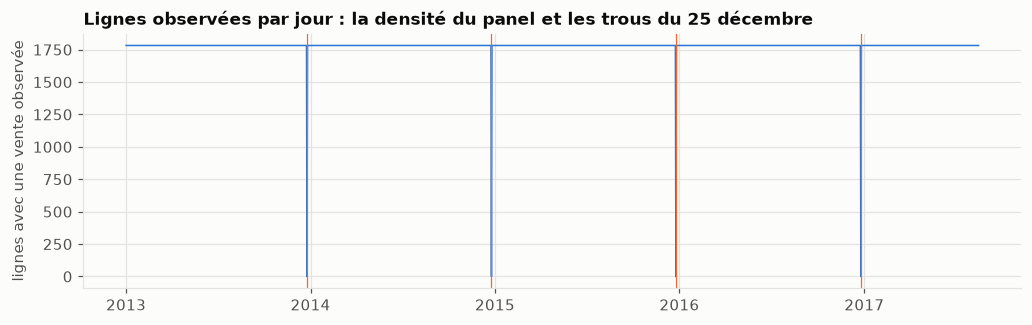

In [2]:
w = load_world()
panel = w.panel
rows_per_day = panel.groupby("date", observed=True)["sales"].count()
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(rows_per_day.index, rows_per_day.values, color=viz.BLUE, linewidth=1)
ax.set_title("Lignes observées par jour : la densité du panel et les trous du 25 décembre")
ax.set_ylabel("lignes avec une vente observée")
for d in rows_per_day.index[rows_per_day == 0]:
    ax.axvline(d, color=viz.ORANGE, linewidth=0.8)
export(fig, "nb01_density")
plt.show()

## 2. Les zéros : structurels ou intermittents ?

**Intuition.** Un zéro le 1er janvier (magasin fermé), un zéro avant l'ouverture d'un magasin, un zéro sur une
famille que le magasin ne vend pas : aucun de ces zéros ne dit « la demande était nulle ». Les traiter comme
des observations biaiserait le niveau et la variance de la série, donc le contrefactuel. Le zéro d'un jour
ordinaire sur une famille à faible volume, lui, est une observation.

**Décision.** Les zéros structurels (`before_opening`, `never_sold`, `closed`) deviennent `NaN` : le modèle
d'espace d'états les traite comme des jours non observés. Les zéros intermittents restent des zéros, sur
l'échelle `log1p`. Rien n'est imputé.

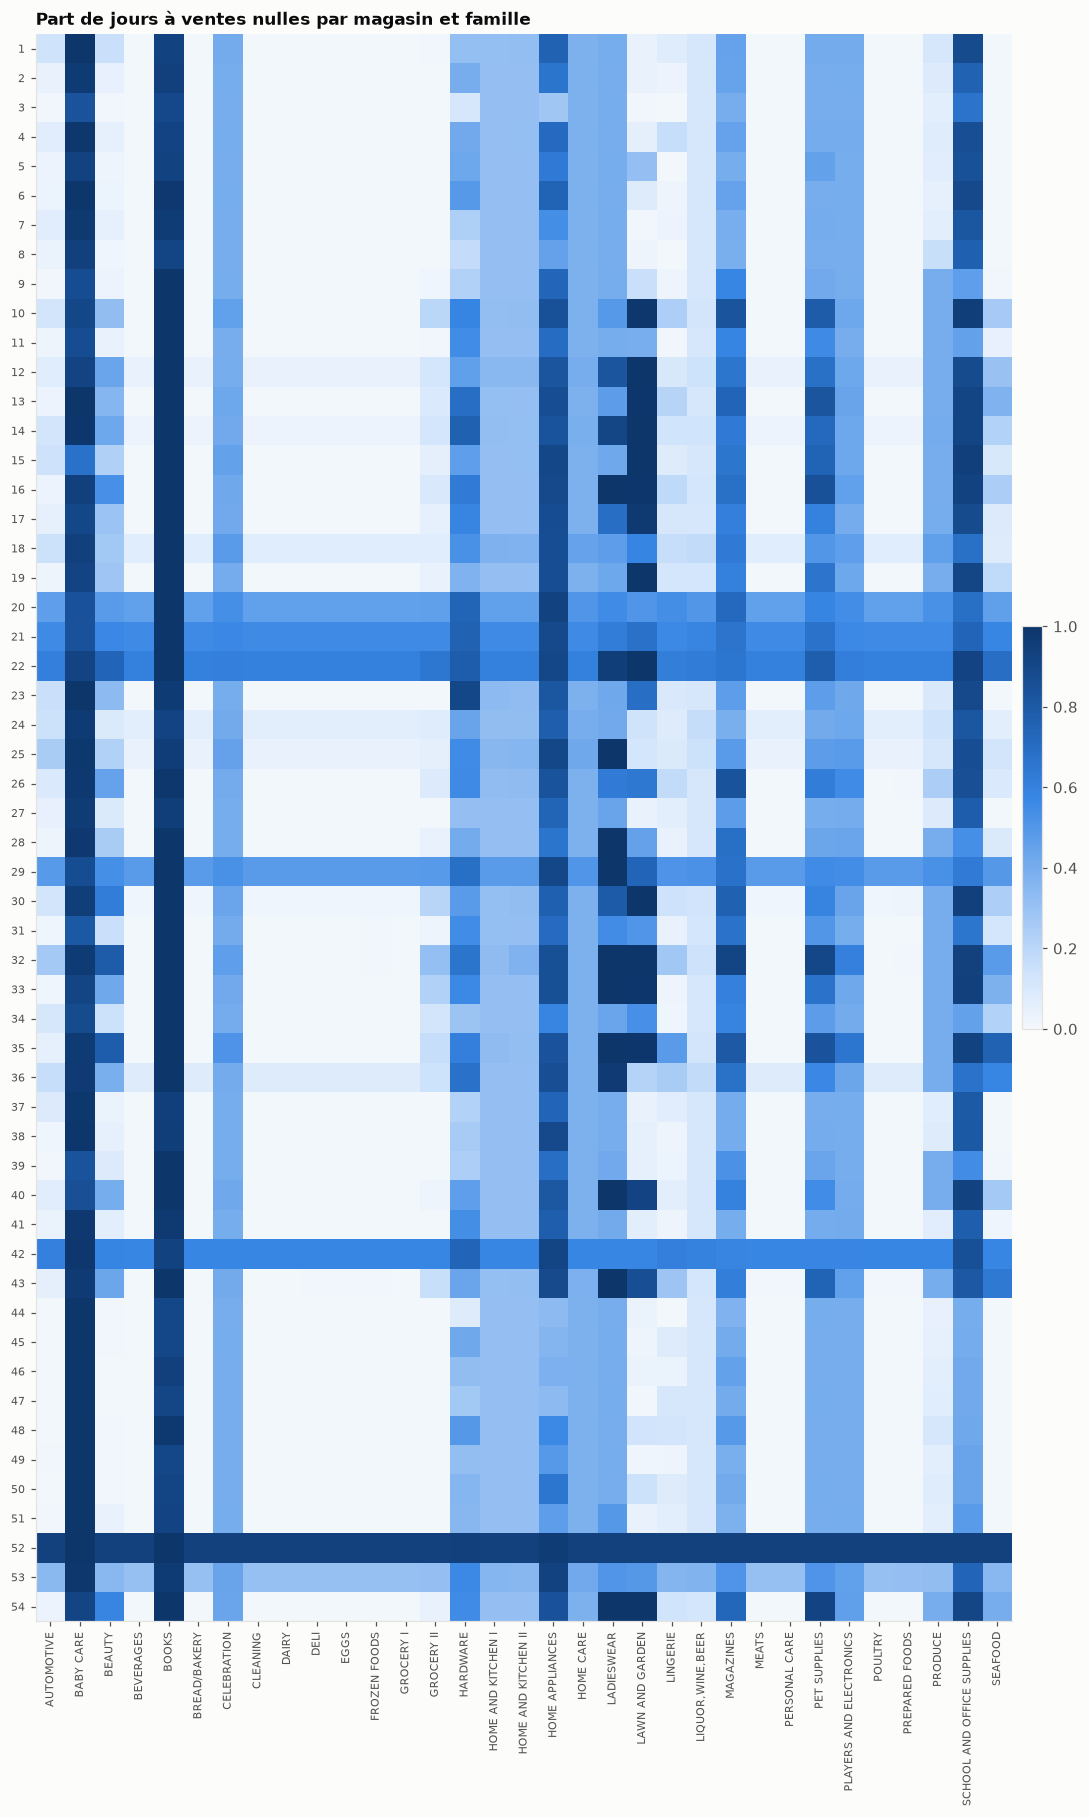

In [3]:
share_zero = (panel.assign(z=(panel["sales"].fillna(0) == 0).astype(float))
              .pivot_table(index="store_nbr", columns="family", values="z", observed=True))
fig, ax = viz.plot_zero_map(share_zero)
export(fig, "nb01_zero_map")
plt.show()

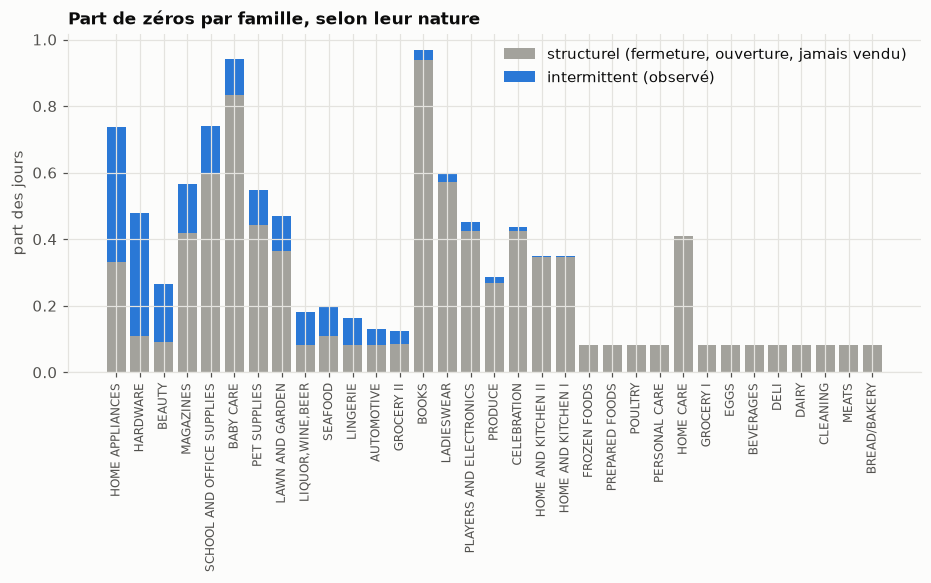

part des zéros du fichier qui sont structurels : 80%


In [4]:
kinds = pd.DataFrame({
    "structurel": panel.groupby("family", observed=True)["structural_zero"].mean(),
    "intermittent": panel.assign(i=(panel["sales"].fillna(0) == 0) & ~panel["structural_zero"])
                         .groupby("family", observed=True)["i"].mean(),
}).sort_values("intermittent", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(kinds.index, kinds["structurel"], color=viz.MUTED, label="structurel (fermeture, ouverture, jamais vendu)")
ax.bar(kinds.index, kinds["intermittent"], bottom=kinds["structurel"], color=viz.BLUE, label="intermittent (observé)")
ax.set_xticks(range(len(kinds)), kinds.index, rotation=90, fontsize=8)
ax.set_ylabel("part des jours")
ax.set_title("Part de zéros par famille, selon leur nature")
ax.legend(loc="upper right")
export(fig, "nb01_zero_kinds")
plt.show()
print(f"part des zéros du fichier qui sont structurels : {rep['share_zero_structural']:.0%}")

**Exemple.** Un magasin ouvert en cours de période : avant l'ouverture, le total journalier est exactement zéro.
Sans le flag, un modèle verrait une « rupture de niveau » et un magasin dont les ventes ont été multipliées par
l'infini.

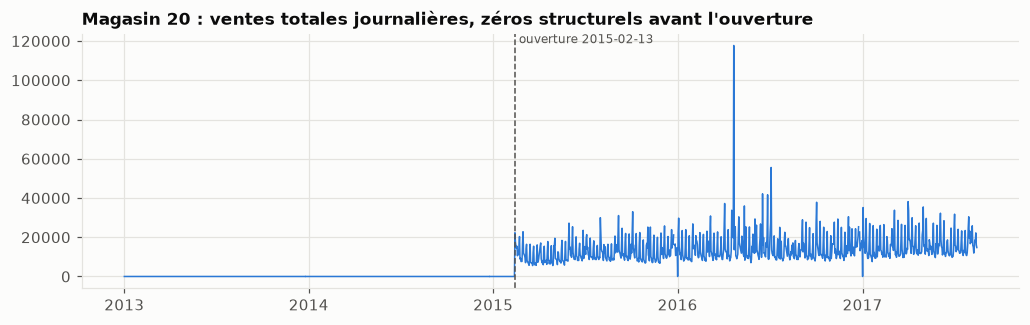

In [5]:
late = list(rep["stores_opened_late"].items())
if late:
    s, d = late[0]
    tot = panel[panel["store_nbr"] == int(s)].groupby("date", observed=True)["sales"].sum(min_count=1)
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(tot.index, tot.values, color=viz.BLUE, linewidth=1)
    viz.mark_intervention(ax, pd.Timestamp(d), f"ouverture {d}")
    ax.set_title(f"Magasin {s} : ventes totales journalières, zéros structurels avant l'ouverture")
    export(fig, "nb01_late_store")
    plt.show()

**Attention.** Le passage en `log1p` est une décision de modélisation, pas une transformation neutre : il rend
les effets multiplicatifs et stabilise la variance, mais sur une série à faible volume il écrase les zéros
contre `log1p(1)`. La figure compare une famille dense et une famille intermittente du même magasin.

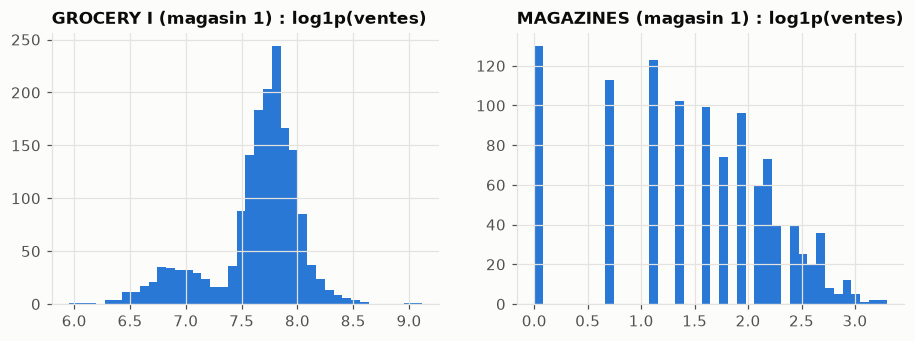

In [6]:
vol = panel[~panel["structural_zero"]].groupby("family", observed=True)["sales"].median().sort_values()
dense, sparse = vol.index[-1], vol.index[max(0, len(vol) // 6)]
store0 = int(panel["store_nbr"].iloc[0])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, fam in zip(axes, (dense, sparse), strict=True):
    s = w.wide[(store0, fam)].dropna()
    ax.hist(np.log1p(s), bins=40, color=viz.BLUE)
    ax.set_title(f"{fam} (magasin {store0}) : log1p(ventes)")
export(fig, "nb01_log1p_hist")
plt.show()

## 3. Le calendrier et les covariables

**Intuition.** Dans `holidays_events.csv`, une ligne `transferred=True` est un férié qui **n'a pas été chômé**
ce jour-là ; le jour chômé est la ligne de type `Transfer`. Les lignes `Bridge` sont des ponts, `Work Day` des
samedis travaillés en compensation, `Event` des événements sans fermeture (dont le séisme). Confondre la date
nominale et la date chômée déplace un creux de ventes d'un jour, exactement l'échelle de temps d'une campagne.

In [7]:
print(holiday_report(w.holidays))
h = w.holidays
print(h[h["transferred"] | (h["type"] == "Transfer")].sort_values("date").head(12).to_string(index=False))

{'rows': 350, 'by_type': {'Holiday': 221, 'Event': 56, 'Additional': 51, 'Transfer': 12, 'Bridge': 5, 'Work Day': 5}, 'transferred': 12, 'transfer_rows': 12, 'earthquake_event_rows': 31, 'by_locale': {'National': 174, 'Local': 152, 'Regional': 24}}
      date     type   locale locale_name                            description  transferred
2012-10-09  Holiday National     Ecuador             Independencia de Guayaquil         True
2012-10-12 Transfer National     Ecuador    Traslado Independencia de Guayaquil        False
2013-10-09  Holiday National     Ecuador             Independencia de Guayaquil         True
2013-10-11 Transfer National     Ecuador    Traslado Independencia de Guayaquil        False
2014-10-09  Holiday National     Ecuador             Independencia de Guayaquil         True
2014-10-10 Transfer National     Ecuador    Traslado Independencia de Guayaquil        False
2016-05-24  Holiday National     Ecuador                   Batalla de Pichincha         True
2016-05

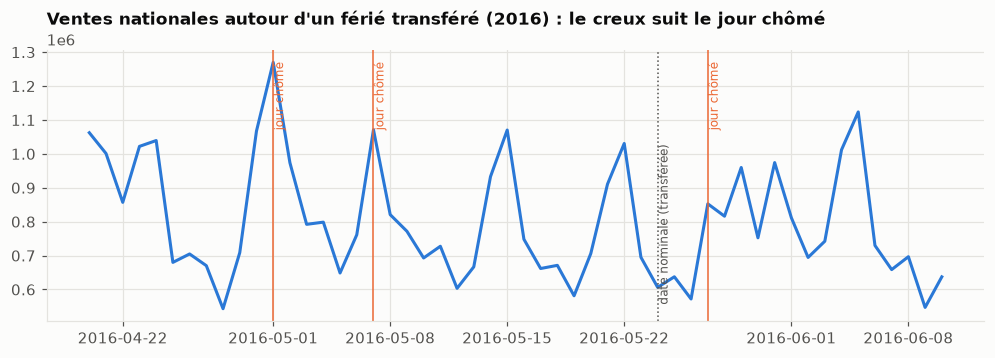

In [8]:
nat = panel[~panel["structural_zero"]].groupby("date", observed=True)["sales"].sum()
off = day_off_table(w.holidays)
off_nat = off[off["locale"] == "National"]["date"]
year = 2016 if (nat.index.year == 2016).any() else nat.index.year.max()
sl = nat.loc[f"{year}-04-20":f"{year}-06-10"]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(sl.index, sl.values, color=viz.BLUE)
for d in off_nat[(off_nat >= sl.index[0]) & (off_nat <= sl.index[-1])]:
    ax.axvline(d, color=viz.ORANGE, linewidth=1)
    ax.text(d, sl.max(), " jour chômé", color=viz.ORANGE, fontsize=8, va="top", rotation=90)
nominal = pd.to_datetime(h.loc[h["transferred"], "date"])
for d in nominal[(nominal >= sl.index[0]) & (nominal <= sl.index[-1])]:
    ax.axvline(d, color=viz.TEXT_2, linewidth=1, linestyle=":")
    ax.text(d, sl.min(), " date nominale (transférée)", color=viz.TEXT_2, fontsize=8, va="bottom", rotation=90)
ax.set_title(f"Ventes nationales autour d'un férié transféré ({year}) : le creux suit le jour chômé")
export(fig, "nb01_transferred")
plt.show()

**Exemple.** La paie bimensuelle (le 15 et le dernier jour du mois) se voit dans le profil moyen des ventes par
jour du mois ; le prix du pétrole, lui, bouge à l'échelle du mois : il n'explique pas une campagne de huit jours
mais il entre comme gradient hebdomadaire dans les régresseurs pour ne pas laisser une tendance lente aux donneurs.

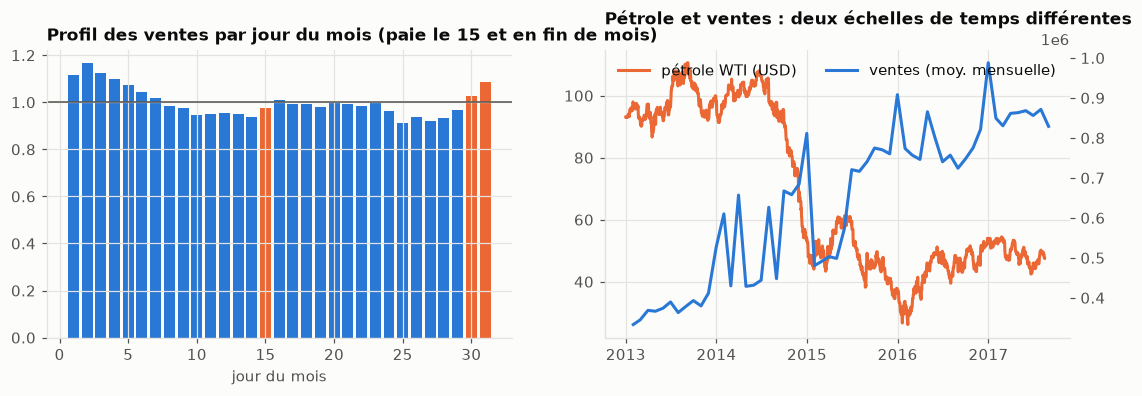

In [9]:
cal = calendar_features(pd.DatetimeIndex(w.wide.index, freq="D"), w.holidays, None, w.oil)
dom = pd.DataFrame({"ventes": nat.values, "jour": nat.index.day}).groupby("jour")["ventes"].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ax = axes[0]
ax.bar(dom.index, dom / dom.mean(), color=[viz.ORANGE if d in (15, 30, 31) else viz.BLUE for d in dom.index])
ax.axhline(1, color=viz.TEXT_2, linewidth=1)
ax.set_title("Profil des ventes par jour du mois (paie le 15 et en fin de mois)")
ax.set_xlabel("jour du mois")
ax = axes[1]
ax.plot(cal.index, np.exp(cal["oil"]), color=viz.ORANGE, label="pétrole WTI (USD)")
ax2 = ax.twinx()
ax2.plot(nat.resample("ME").mean().index, nat.resample("ME").mean().values, color=viz.BLUE, label="ventes (moy. mensuelle)")
ax2.grid(False)
ax.set_title("Pétrole et ventes : deux échelles de temps différentes")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
export(fig, "nb01_payday_oil")
plt.show()

## 4. `onpromotion` : une intensité, pas un drapeau

**Attention.** `onpromotion` compte les articles de la famille en promotion ce jour-là dans ce magasin. Il est
nul avant avril 2014 (information absente, remplie par zéro dans le fichier : flag `promo_unknown`), puis
rarement nul pour les grandes familles. « Être en promotion » n'est donc pas un événement : la plupart des
familles le sont en permanence à bas niveau. Une campagne est un **saut** au-dessus de ce fond, et c'est ce que
le notebook 02 détecte.

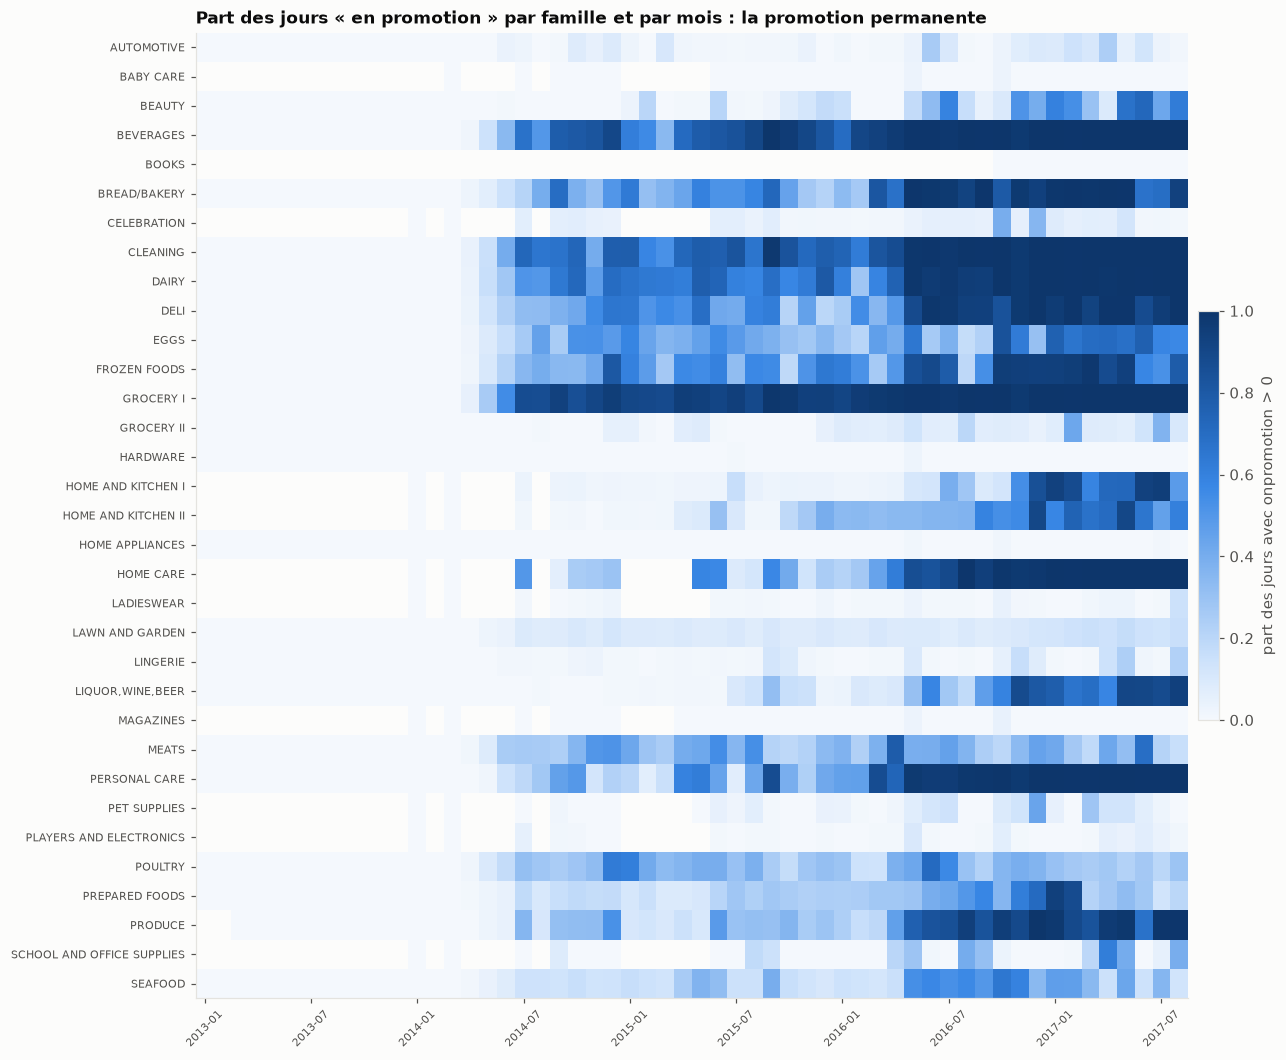

In [10]:
pm = (panel[~panel["structural_zero"]].assign(month=panel["date"].dt.to_period("M").dt.to_timestamp())
      .groupby(["family", "month"], observed=True)["onpromotion"].apply(lambda s: (s > 0).mean()).unstack("month"))
fig, ax = plt.subplots(figsize=(12, 0.3 * len(pm) + 1.5))
im = ax.imshow(pm.values, aspect="auto", cmap=viz.base.SEQUENTIAL, vmin=0, vmax=1)
ax.set_yticks(range(len(pm)), pm.index, fontsize=7)
ticks = list(range(0, pm.shape[1], 6))
ax.set_xticks(ticks, [pm.columns[t].strftime("%Y-%m") for t in ticks], rotation=45, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="part des jours avec onpromotion > 0")
ax.set_title("Part des jours « en promotion » par famille et par mois : la promotion permanente")
export(fig, "nb01_promo_share")
plt.show()

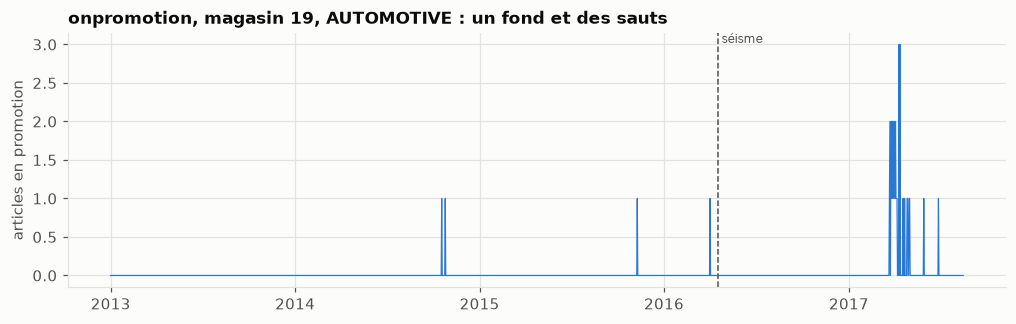

In [11]:
store_fam = w.units[len(w.units) // 3]
c = w.wide_promo[store_fam]
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(c.index, c.values, color=viz.BLUE, linewidth=0.8)
ax.set_title(f"onpromotion, magasin {store_fam[0]}, {store_fam[1]} : un fond et des sauts")
ax.set_ylabel("articles en promotion")
viz.mark_intervention(ax, QUAKE, "séisme")
export(fig, "nb01_onpromotion_series")
plt.show()

## À retenir

- Le panel est dense ; seul le 25 décembre manque. La vraie décision porte sur les **zéros structurels**, mis à
  `NaN`, et non sur une reconstruction de zéros.
- Les fériés sont lus à la date **chômée** (lignes `Transfer`), pas à la date nominale.
- La paie bimensuelle et le jour de la semaine sont des régresseurs déterministes ; le pétrole entre en gradient.
- `onpromotion` est une intensité avec un fond permanent : le traitement doit être **construit** (notebook 02),
  et la période antérieure à avril 2014 est inutilisable comme pré-période (statut promotionnel inconnu).